# **SIADS 521 Assignment 3 — Exploring 50 Years of the U.S. Economy**

Four linked Plotly charts · Public-domain economic data · Offline HTML dashboard \
Dashboard link: https://beromanowski7.github.io/SIADS521-Dashboard/

## **Author:** Blake Romanowski

**AI disclosure:** ChatGPT assisted with data preparation, example code, dashboard design, browser testing, and this notebook. The findings below were calculated from the dataset; The AI log entries at the end of the notebook aim to document errors caught.

---
## 1. **Introduction**
---

This dashboard asks how inflation, unemployment, and real GDP growth differed across U.S. decades between 1959 and 2009. Its intended audience is students or analysts learning to compare economic indicators without treating a national 50-year average as representative of every period. Filters re-draw all four charts at once.

**Interactive dashboard:** Open `index.html` next to this notebook. This is a self-contained HTML fallback rather than a hosted link.

**Screenshot of full dashboard:**

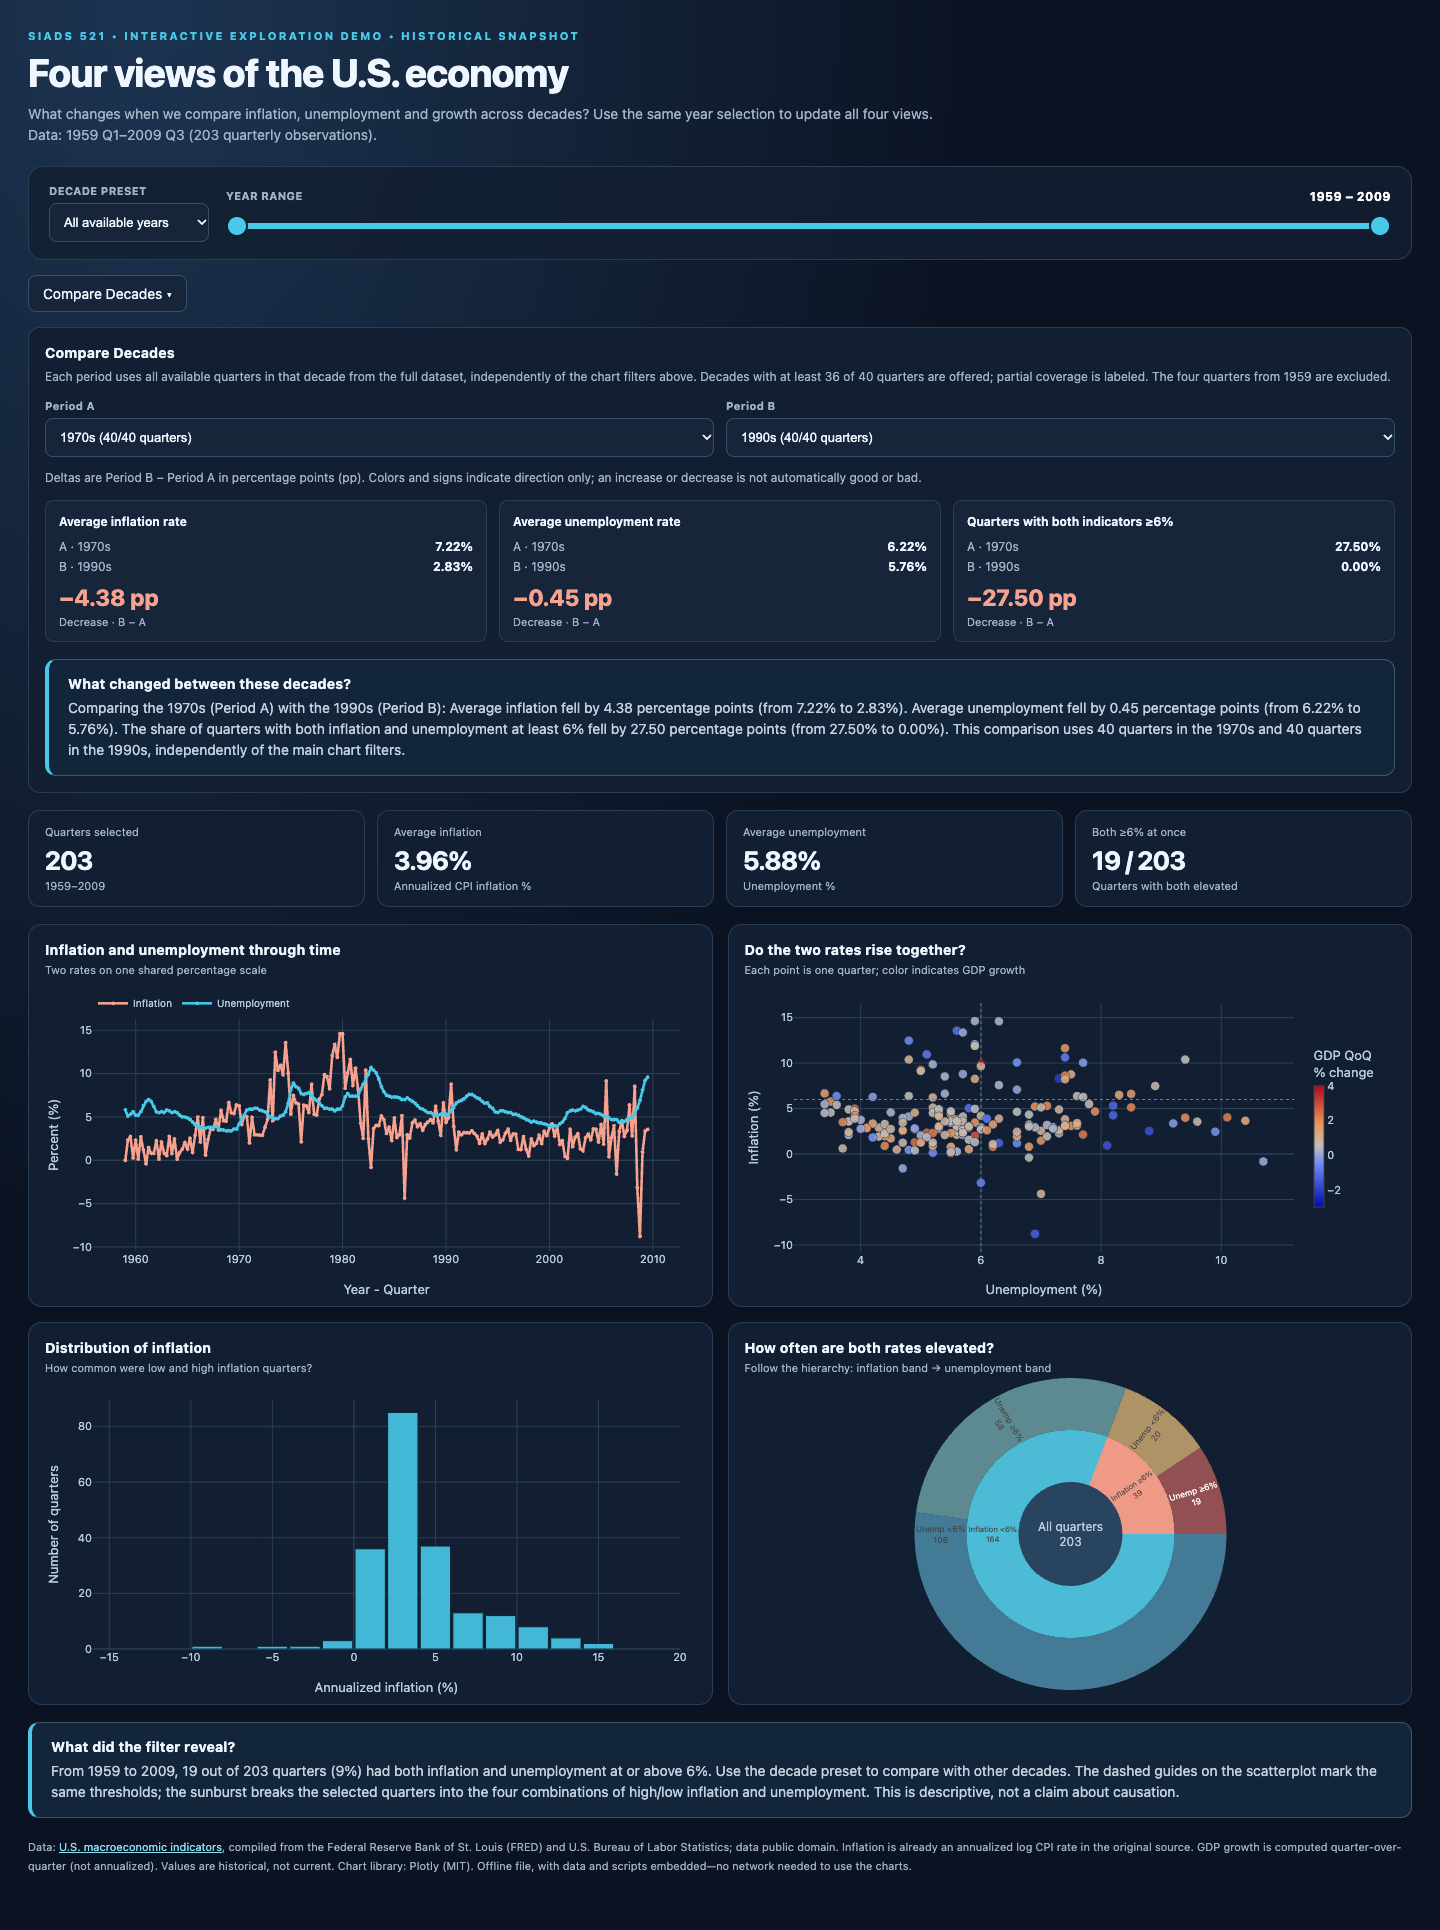


---
## 2. Library choice and fit
---

I used **Plotly.py**, the open-source charting library created and maintained by Plotly, Inc. Its code is available under the **MIT license**, and it can be installed with `pip install plotly` (plus pandas for tabular data). Plotly Express is largely *declarative*: I supply a dataset and mappings like `x="unemp"` and `y="infl"`. The lower-level Graph Objects API also provides a *procedural* way to build and customize figures trace by trace. The dashboard uses Plotly.js for four linked browser charts, produced from Python.

Plotly works directly in Jupyter via `fig.show()`; charts can also be exported as standalone HTML. This matters because graders must open the dashboard without installing Python. Embedding Plotly.js and the small dataset in the file creates a repeatable offline experience. I did not choose Dash because it normally requires hosting a running Python service. I considered **Bokeh**, which can also generate standalone JavaScript-driven HTML, but chose Plotly for its sunburst support, concise Python examples, and consistent hover/zoom interactions.

There are tradeoffs. A standalone Plotly figure supports its own hover and selection, but linking **four** exported figures with shared filters requires some browser JavaScript. Including Plotly.js produces an HTML file several megabytes in size. A first version using a WebGL-dependent parallel-coordinates plot also failed in a headless Chromium test; switching the novel visualization to a non-WebGL sunburst reduced that compatibility risk. This is not a claim that parallel coordinates is always unsupported: support varies by browser and hardware.

**Why this match?** The dataset is a compact quarterly time series with multiple quantitative variables and meaningful decade groups. Plotly supports temporal comparison, bivariate correlation exploration, distributions, and a hierarchical chart in one page while keeping the underlying data visible on hover.

Reference: [Plotly Python repository and documentation](https://github.com/plotly/plotly.py) and [HTML export guidance](https://plotly.com/python/interactive-html-export/).



---
## **3. Data: source, license and cleaning**
---

The dataset is `statsmodels.datasets.macrodata`: 203 quarterly records from **1959 Q1 through 2009 Q3** and 14 original columns. It was compiled by Skipper Seabold from the Federal Reserve Bank of St. Louis/FRED and the U.S. Bureau of Labor Statistics. The dataset's documentation explicitly identifies its copyright as **public domain**. It is not live 2026 economic data.

Variables used are year, quarter, real GDP, inflation (`infl`, an already annualized CPI-based rate), unemployment (`unemp`, percent), and three-month Treasury bill rate (`tbilrate`, percent). The source also contains consumption and investment. I created quarter labels and dates to support filtering and added **quarter-over-quarter real GDP growth** as `100 * pct_change(realgdp)`. This is *not annualized* GDP growth. I added an illustrative 6% joint-high flag, not an official economic classification.

The steps below load the original source, sort records, coerce numeric columns, check missing values, create derived fields, and save a CSV. Since the first record has no prior GDP quarter, its calculated growth is missing and is omitted from the GDP-colored scatter only. No other rows are silently deleted.

Source and attribution: [statsmodels macrodata documentation](https://www.statsmodels.org/stable/datasets/generated/macrodata.html); [public-domain notice in source](https://github.com/statsmodels/statsmodels/blob/main/statsmodels/datasets/macrodata/data.py).


In [ ]:
# Dependencies: pip install plotly pandas statsmodels
import pandas as pd
import plotly.express as px
from pathlib import Path
import statsmodels.api as sm

raw = sm.datasets.macrodata.load_pandas().data.copy()
print('Original rows and columns:', raw.shape)
print('Missing original values:', int(raw.isna().sum().sum()))
raw.head(3)

Original rows and columns: (203, 14)
Missing original values: 0


,year,quarter,realgdp,realcons,realinv,realgovt,realdpi,cpi,m1,tbilrate,unemp,pop,infl,realint
0,1959.0,1.0,2710.349,1707.4,286.898,470.045,1886.9,28.98,139.7,2.82,5.8,177.146,0.00,0.00
1,1959.0,2.0,2778.801,1733.7,310.859,481.301,1919.7,29.15,141.7,3.08,5.1,177.830,2.34,0.74
2,1959.0,3.0,2775.488,1751.8,289.226,491.260,1916.4,29.35,140.5,3.82,5.3,178.657,2.74,1.09


In [ ]:
# Cleaning and feature derivation (same operations as build_dashboard.py)
df = raw.sort_values(['year', 'quarter']).reset_index(drop=True).copy()
for name in ['realgdp', 'realcons', 'realinv', 'tbilrate', 'unemp', 'infl']:
    df[name] = pd.to_numeric(df[name], errors='coerce')
df['year'] = df['year'].astype(int)
df['quarter'] = df['quarter'].astype(int)
assert len(df) == 203 and not df[['realgdp','unemp','infl']].isna().any().any()

df['period'] = df['year'].astype(str) + ' Q' + df['quarter'].astype(str)
df['date'] = pd.PeriodIndex.from_fields(year=df['year'], quarter=df['quarter'], freq='Q').to_timestamp()
df['decade'] = df['year'] // 10 * 10
df['gdp_growth_qoq'] = 100 * df['realgdp'].pct_change()  # first row: missing by design
df['investment_share'] = 100 * df['realinv'] / df['realgdp']
df['joint_high'] = (df['infl'] >= 6) & (df['unemp'] >= 6)
print('Derived missing GDP-growth values:', int(df['gdp_growth_qoq'].isna().sum()))
print('Periods:', df['period'].iloc[0], 'to', df['period'].iloc[-1])
df.to_csv('macrodata_clean.csv', index=False)

Derived missing GDP-growth values: 1
Periods: 1959 Q1 to 2009 Q3



---
## **4. Visualization techniques and why they work together**
---

**Line chart** — A joint time-series line chart compares the paths of inflation and unemployment in percentage units. It is useful for spotting periods of movement and divergence. \
**When not to use it:** when the measures have incompatible units or dense timestamps make trajectories unreadable. I used a shared percent axis instead of misleading dual y-axes.

**Scatterplot** — Each quarter is a point with unemployment on x, inflation on y and quarter-over-quarter GDP growth mapped to color. Dashed 6% threshold lines allow us to identify quarters in the upper-right quadrant. It helps explore co-occurrence, not causation. \
**When not to use it:** if timing/order is the central question or the point cloud is highly overplotted.

**Histogram** — A fixed 2-percentage-point bin width shows how the inflation distribution shifts when a decade is chosen. Using identical bin edges across filters makes period comparisons fairer. \
**When not to use it:** with very few data points or when precise quarter identities matter; binning hides detail.

**Sunburst (method new to SIADS 521)** — The inner ring divides the selected quarters into `inflation ≥6%` versus `inflation <6%`; the next ring divides each group by unemployment above/below 6%. The **slice area represents counts**, revealing the joint combinations and their prevalence. A simple bar plot of overall inflation could not simultaneously display the nested breakdown of two categorical conditions. \
**When not to use it:** for many hierarchy levels, many tiny categories, or when exact numeric comparisons between slices are critical. Hover counts and summary labels are included for that reason.

**Arrangement:** top-left provides historical context; top-right tests the relationship; bottom-left shows the distribution; bottom-right summarizes joint membership in a compact hierarchy. All four change when the decade or year-range filter changes.



---
## **5. Building and exploring: in stages**
---
### Stage A — Build the first readable charts

I began by making the time-series plot with correctly labeled percent units, then the scatterplot. The figures below use high-level Plotly Express, so a classmate can experiment before reading the offline JavaScript dashboard code. In the standalone dashboard, the same four views use lower-level Plotly traces updated by one browser-side filter function.

**Early build screenshot (the first line chart):**

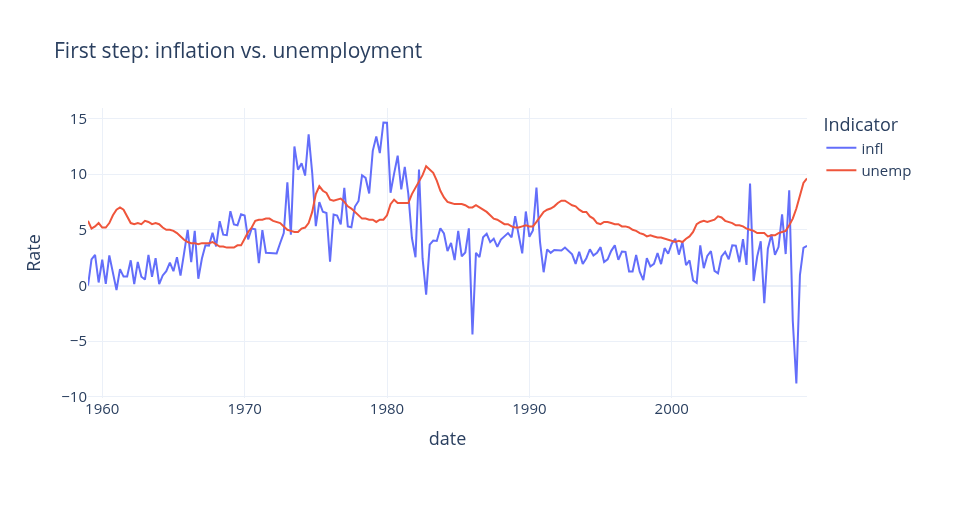


In [ ]:
# Stage A: a basic line chart
long = df.melt(id_vars=['date', 'period'], value_vars=['infl', 'unemp'],
               var_name='Indicator', value_name='Rate (%)')
fig1 = px.line(long, x='date', y='Rate (%)', color='Indicator',
               title='Inflation and unemployment by quarter')
fig1.update_layout(template='plotly_white')
fig1.show()

In [ ]:
# Stage B: relationship scatterplot, with GDP growth as a third variable
scatter_data = df.dropna(subset=['gdp_growth_qoq']).copy()
fig2 = px.scatter(scatter_data, x='unemp', y='infl', color='gdp_growth_qoq',
                  hover_name='period', color_continuous_scale='RdYlBu',
                  labels={'unemp':'Unemployment (%)', 'infl':'Inflation (%)',
                          'gdp_growth_qoq':'Real GDP QoQ growth (%)'})
fig2.add_vline(x=6, line_dash='dash')
fig2.add_hline(y=6, line_dash='dash')
fig2.show()


---
### Stage B — Add a distribution and a novel hierarchical chart

The dashboard histogram keeps consistent 2-point inflation bins; the standalone notebook example below uses automatic bins. The sunburst needs a tidy table of unique category combinations, so I grouped each quarter into a high/low inflation label and a high/low unemployment label, then counted the rows. This makes the sunburst's geometry auditably tied to raw row counts. It is important not to supply incompatible parent totals because Plotly's sunburst `branchvalues` rules are strict.


In [ ]:
# Stage C: histogram
px.histogram(df, x='infl', nbins=18,
             title='Inflation distribution: 1959 Q1–2009 Q3',
             labels={'infl':'Annualized inflation (%)'}).show()

# Stage D: standalone sunburst example with count aggregation
sun = df.copy()
sun['Inflation group'] = sun['infl'].ge(6).map({True:'Inflation >=6%', False:'Inflation <6%'})
sun['Unemployment group'] = sun['unemp'].ge(6).map({True:'Unemployment >=6%', False:'Unemployment <6%'})
counts = sun.groupby(['Inflation group','Unemployment group']).size().reset_index(name='Quarters')
fig4 = px.sunburst(counts, path=['Inflation group','Unemployment group'], values='Quarters',
                   title='Joint high/low categories (counts of quarters)')
fig4.show()


---
### Stage C — Combine the views and connect the controls

A dropdown selects a decade preset, and a dual-handle year-range slider selects a custom window. In the HTML file, the `update()` function filters the embedded records once, calculates the summary metrics, and passes the resulting subset to **each of four `Plotly.react()` calls**. The design uses one data state for all views, so switching from 1970s to 1990s never leaves one chart displaying stale records. Hover over marks for quarter-level details.

A one-file browser dashboard was chosen over Dash because it meets the assignment's no-install fallback. Python packages are only required to regenerate or edit the dashboard; someone opening the finished HTML file needs just a modern browser. The full implementation is in `build_dashboard.py`.

**Finished dashboard in the 1970s state:**

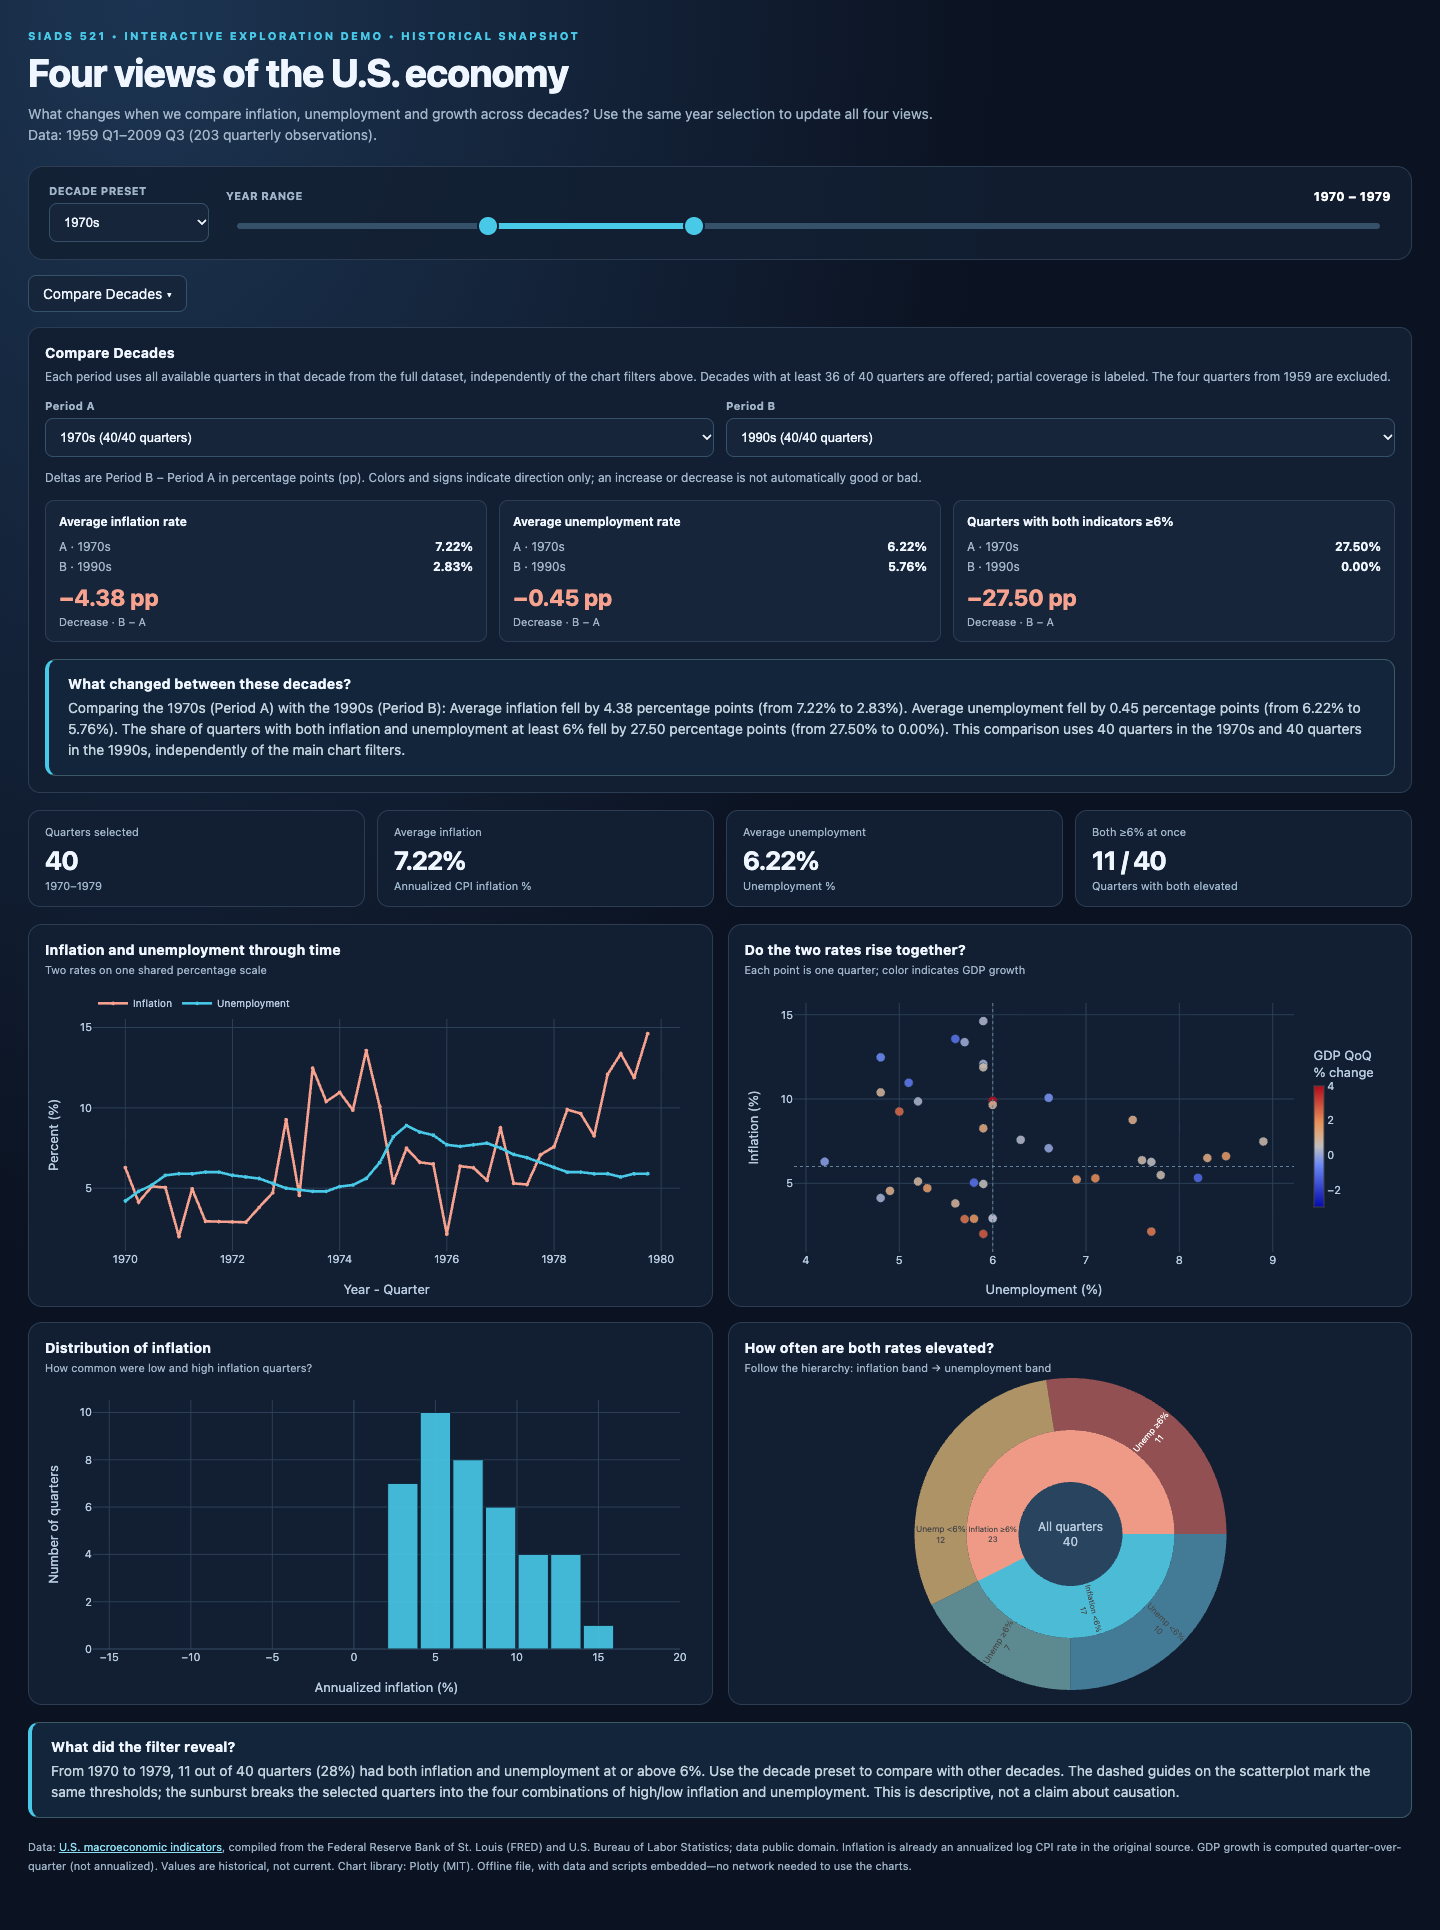


In [ ]:
# Build/export the fully offline HTML file.
# This is a companion-source-file import, so keep build_dashboard.py next to the notebook.
from build_dashboard import create_dashboard
output_file = create_dashboard(df)
print('Open this file in a browser:', output_file.name)

Created index.html (4.9 MB) and macrodata_clean.csv (203 rows)
Open this file in a browser: index.html



---
### Stage D — Explore: decade differences, outliers, and threshold sensitivity

**Starting question:** Do decades with higher average inflation also have higher unemployment in every quarter? The shared decade filter isolates each period across the line chart, scatterplot, histogram, sunburst, and summary counters. Compare Decades then places the decade-level values side by side while using the full dataset independently of the main chart filters.

**Verified decade comparison:** The grouped table below confirms that the 1970s had **11 of 40 quarters (27.5%)** with inflation and unemployment both at least 6%, compared with **0 of 40 (0%)** in the 1990s. Average inflation was **7.22% versus 2.83%**, and average unemployment was **6.22% versus 5.76%**. The 1980s had **8 of 40** joint-high quarters, while the 2000s had **0 of 39**, with coverage ending in 2009 Q3. The dashboard's displayed decade counters were checked against these grouped calculations.

**Quarter-level tooltip checks:** Codex used automated Plotly hover events in headless Chrome to inspect five rendered scatterplot tooltips and matched their values to the cleaned records. Inflation is already annualized in the source; GDP growth below is quarter-over-quarter and not annualized.

| Quarter | Inflation | Unemployment | Real GDP growth, QoQ |
| --- | --- | --- | --- |
| 1979 Q4 — highest inflation | 14.62% | 5.90% | 0.28% |
| 2008 Q4 — lowest inflation | −8.79% | 6.90% | −1.37% |
| 1982 Q4 — highest unemployment | −0.82% | 10.70% | 0.08% |
| 1978 Q2 — highest GDP growth | 9.89% | 6.00% | 3.93% |
| 1980 Q2 — lowest GDP growth | 8.32% | 7.30% | −2.05% |

**Unexpected finding 1 — the inflation peak is outside the joint-high category:** In 1979 Q4, inflation reached 14.62%, yet unemployment was 5.9%, just below the 6% cutoff. In fact, all four quarters of 1979 had inflation above 11% and unemployment between 5.7% and 5.9%, so none met the original joint-high rule. Filtering to the late 1970s and inspecting individual points reveals a detail that the decade's count alone conceals. The highest unemployment quarter, 1982 Q4, also had slightly negative inflation rather than high inflation. The two variables' extremes therefore did not occur together in these quarters.

**Unexpected finding 2 — zero joint-high quarters does not mean an uneventful decade:** The 2000s had no quarters satisfying both thresholds, but the 2008 Q4 tooltip shows −8.79% inflation, 6.9% unemployment, and a 1.37% quarter-over-quarter GDP decline. This quarter is excluded from the joint-high category because inflation was negative. The line chart and scatterplot expose a different combination of conditions that the single threshold counter cannot summarize.

**Sensitivity check:** Keeping inflation at **≥6%** but lowering the unemployment cutoff to **≥5.5%** increases the 1970s count to **17/40 (42.5%)** and the 1990s count to **1/40 (2.5%)**. All four quarters of 1979 now qualify; 1990 Q3 also qualifies, with inflation of 8.79% and unemployment of 5.7%. The 1970s still show more frequent simultaneous threshold exceedance, but the exact counts—and the claim of zero qualifying quarters in the 1990s—depend on the chosen cutoff. This alternative is calculated only in the audit cell below; the dashboard retains its original **≥6% for both indicators** rule.

**Why interaction matters:** A full-period average mixes these different combinations. Decade filtering, quarter-level tooltips, and the comparison panel make it possible to move between the overall pattern and observations near a category boundary. These are descriptive, dataset-specific findings, not evidence of causation or statements about current economic conditions.

**Verification and AI use:** The tooltip inspection, grouped-count checks, and threshold sensitivity calculation in this section were performed with Codex assistance. This section reports those checks rather than treating them as unverified personal browser-testing claims. The following cell reproduces the numerical checks without modifying the dashboard.


In [ ]:
# Reproduce Stage D findings without changing the dashboard's 6% thresholds.
from IPython.display import display

analysis_data = df[df['year'].between(1960, 2009)].copy()
summary = (analysis_data.groupby('decade')
           .agg(quarters=('period', 'size'), avg_inflation=('infl', 'mean'),
                avg_unemployment=('unemp', 'mean'),
                high_both=('joint_high', 'sum')))
summary['fraction_high_both'] = summary['high_both'] / summary['quarters']
assert summary.loc[1970, 'quarters'] == 40 and summary.loc[1970, 'high_both'] == 11
assert summary.loc[1990, 'quarters'] == 40 and summary.loc[1990, 'high_both'] == 0
print('Baseline grouped decade table: inflation >=6%, unemployment >=6%')
display(summary.round(3))

# Match the five inspected browser tooltips to the cleaned quarterly records.
outlier_periods = ['1979 Q4', '2008 Q4', '1982 Q4', '1978 Q2', '1980 Q2']
outlier_audit = df.set_index('period').loc[
    outlier_periods, ['infl', 'unemp', 'gdp_growth_qoq']]
assert df.loc[df['infl'].idxmax(), 'period'] == '1979 Q4'
assert df.loc[df['infl'].idxmin(), 'period'] == '2008 Q4'
assert df.loc[df['unemp'].idxmax(), 'period'] == '1982 Q4'
assert df.loc[df['gdp_growth_qoq'].idxmax(), 'period'] == '1978 Q2'
assert df.loc[df['gdp_growth_qoq'].idxmin(), 'period'] == '1980 Q2'
print('Outlier records: inflation and unemployment in %, GDP growth in QoQ %')
display(outlier_audit.round(3))

# Sensitivity check only: keep inflation >=6%, lower unemployment to >=5.5%.
analysis_data['alternative_high_both'] = (
    analysis_data['infl'].ge(6) & analysis_data['unemp'].ge(5.5))
threshold_comparison = (analysis_data.groupby('decade')
    .agg(quarters=('period', 'size'), baseline_count=('joint_high', 'sum'),
         alternative_count=('alternative_high_both', 'sum')))
threshold_comparison['baseline_percent'] = (
    100 * threshold_comparison['baseline_count'] / threshold_comparison['quarters'])
threshold_comparison['alternative_percent'] = (
    100 * threshold_comparison['alternative_count'] / threshold_comparison['quarters'])
assert threshold_comparison.loc[1970, 'alternative_count'] == 17
assert threshold_comparison.loc[1990, 'alternative_count'] == 1
print('Threshold comparison: unemployment >=6% versus >=5.5%; inflation stays >=6%')
display(threshold_comparison.round(2))


Baseline grouped decade table: inflation >=6%, unemployment >=6%


,quarters,avg_inflation,avg_unemployment,high_both,fraction_high_both
decade,,,,,
1960,40,2.550,4.782,0,0.000
1970,40,7.217,6.215,11,0.275
1980,40,4.914,7.277,8,0.200
1990,40,2.835,5.765,0,0.000
2000,39,2.517,5.415,0,0.000


Outlier records: inflation and unemployment in %, GDP growth in QoQ %


,infl,unemp,gdp_growth_qoq
period,,,
1979 Q4,14.62,5.9,0.275
2008 Q4,-8.79,6.9,-1.371
1982 Q4,-0.82,10.7,0.079
1978 Q2,9.89,6.0,3.934
1980 Q2,8.32,7.3,-2.049


Threshold comparison: unemployment >=6% versus >=5.5%; inflation stays >=6%


,quarters,baseline_count,alternative_count,baseline_percent,alternative_percent
decade,,,,,
1960,40,0,0,0.0,0.0
1970,40,11,17,27.5,42.5
1980,40,8,8,20.0,20.0
1990,40,0,1,0.0,2.5
2000,39,0,0,0.0,0.0



---
## **6. AI log and troubleshooting**

**AI disclosure:** ChatGPT assisted with initial dashboard code, chart design, data preparation, browser testing, and notebook drafting. Codex subsequently reviewed the source for potential problems. I am aware that I am responsible for independently verifying the code, findings, and fixes. Entries below that describe completed changes that were checked against my own testing before submission.

---

### Entry 1: JSON contained an illegal `NaN`

**Tool:**
ChatGPT and Python

**What I asked for / what I was trying to do:**
I wanted to embed the cleaned dataset in a single offline HTML file so the dashboard could filter records without a Python server.

**What came back / what happened:**
During the initial build, Python raised `ValueError: Out of range float values are not JSON compliant: nan` when serializing the data to JSON.

**What was wrong or could be better:**
The first quarter had an undefined calculated GDP growth value. Using `DataFrame.where(..., None)` on a float column did not actually replace the NumPy `NaN` value with a JSON-compatible `null`.

**How I noticed:**
The export script failed with an exception before the HTML file could be generated.

**What I did instead:**
The code was changed to cast values to Python objects using `.astype(object)` before replacing missing values with `None`. Using `allow_nan=False` also makes future invalid JSON values trigger an error instead of being silently exported.

**What I learned:**
Missing values that work inside pandas do not always serialize directly into valid JSON. Data validation matters when moving data between Python and a browser.

---

### Entry 2: A chart rendered a WebGL warning

**Tool:**
ChatGPT, Plotly, and Chromium

**What I asked for / what I was trying to do:**
I wanted a visualization method that was new to SIADS 521 and could compare multiple economic indicators.

**What came back / what happened:**
The original dashboard included a parallel-coordinates chart, but the chart area showed a warning indicating that WebGL was unsupported in the headless test browser.

**What was wrong or could be better:**
The design depended on graphics capabilities that were unavailable in that testing environment, which reduced confidence in its portability.

**How I noticed:**
The browser-test screenshot displayed a warning where the fourth chart should have appeared, although the other charts rendered correctly.

**What I did instead:**
The parallel-coordinates chart was replaced with a Plotly sunburst chart showing combinations of high and low inflation and unemployment. The prototype was retested, including its dropdown interaction, without reported JavaScript page errors.

**What I learned:**
A technically valid visualization may still be a poor choice if it does not render reliably for viewers. Compatibility is part of choosing an appropriate visualization method.

---

### Entry 3: Shared filtering needed an explicit test

**Tool:**
ChatGPT and Playwright

**What I asked for / what I was trying to do:**
I needed to confirm that the decade selector updated the entire dashboard rather than changing only one chart.

**What came back / what happened:**
The original automated test reported 203 observations overall. The 1970s selection showed 40 quarters, including 11 with both inflation and unemployment at least 6%; the 1990s showed 40 quarters, with zero meeting both thresholds.

**What was wrong or could be better:**
A functioning default dashboard does not prove that its linked interactions work. A static screenshot could also conceal filtering errors.

**How I noticed:**
The test changed the decade selection, inspected the displayed counts, and checked for JavaScript page errors.

**What I did instead:**
The prototype included explicit before-and-after filter checks and a separate summary calculation to compare the reported counts with the underlying data.

**What I learned:**
Interactive dashboards need tests of changing states, not just tests that the initial page opens correctly.

---

### Entry 4: Successfully creating a standalone dashboard

**Tool:**
ChatGPT, Plotly, and Safari

**What I asked for / what I was trying to do:**
I wanted an interactive dashboard that could be shared without requiring users to install Python or run a server.

**What came back / what happened:**
ChatGPT generated Python code that exported the dashboard into a standalone HTML file.

**What was wrong or could be better:**
This was a successful use of AI rather than a demonstrated error. The generated HTML included the necessary Plotly code and dataset, removing the need for separate files during viewing.

**How I noticed:**
I ran the Python script and successfully opened the resulting HTML dashboard in Safari.

**What I did instead:**
Rather than requiring a hosted Python application, I used the generated standalone HTML file and tested it in a browser.

**What I learned:**
Plotly can create shareable interactive visualizations that viewers can open without installing a programming environment.

---

### Entry 5: Correct implementation of linked filtering

**Tool:**
ChatGPT and Plotly

**What I asked for / what I was trying to do:**
I wanted selecting a decade to update several charts together, so the user would always be comparing the same time period.

**What came back / what happened:**
ChatGPT generated JavaScript that applies a shared dataset filter and updates the Plotly visualizations using `Plotly.react()`.

**What was wrong or could be better:**
The overall filtering design was appropriate. However, it still needed explicit testing because a correct-looking initial view did not prove that every chart responded consistently.

**How I noticed:**
The source used shared filter logic, and the 1970s-versus-1990s comparison could be checked against the underlying dataset.

**What I did instead:**
I kept the linked-filter design and used decade-level count comparisons as a way to validate its behavior.

**What I learned:**
Using one shared filtered dataset helps maintain consistency across the charts, but the interaction must still be tested with different selections.

---

### Entry 6: The 6% threshold was too simplistic

**Tool:**
ChatGPT

**What I asked for / what I was trying to do:**
I wanted to identify periods when inflation and unemployment were both elevated.

**What came back / what happened:**
ChatGPT used a fixed 6% cutoff for each indicator and counted the quarters meeting both conditions.

**What was wrong or could be better:**
The cutoff was a convenient exploratory choice rather than an official economic classification. In 1979, unemployment ranged from 5.7% to 5.9%, so all four quarters fell below the joint threshold despite very high inflation.

**How I noticed:**
Reviewing the quarterly data showed that observations close to the cutoff could change categories even when their economic conditions were quite similar.

**What I did instead:**
I treated the 6% rule as an explicitly stated analytical assumption. A useful sensitivity check would lower the unemployment cutoff to 5.5%, which would cause all four quarters in 1979 to meet the combined condition. This is a proposed check, not a claim that the dashboard's threshold has been changed.

**What I learned:**
Thresholds simplify comparisons, but they can also hide meaningful differences near the boundary. Conclusions should identify the assumptions used to define categories.

---

### Entry 7: Leftover code naming from an earlier visualization

**Tool:**
ChatGPT

**What I asked for / what I was trying to do:**
I needed to replace the original parallel-coordinates chart with a sunburst chart that would render more reliably.

**What came back / what happened:**
ChatGPT replaced the visualization, but the element containing the new sunburst was still named `parallelplot`.

**What was wrong or could be better:**
The code could still function, but the identifier no longer described the visualization accurately. This could confuse someone reading or maintaining the source.

**How I noticed:**
Reviewing the generated source revealed that the earlier chart name remained after the replacement.

**What I did instead:**
The recommended cleanup is to rename the identifier consistently to `sunburstplot`, rebuild the HTML, and test the chart again. This should only be marked complete after the change is actually made.

**What I learned:**
AI-generated code can appear to work while retaining misleading names and other maintainability problems. Source review remains valuable after functionality is achieved.

---

### Entry 8: Correctly documenting the limitations of historical data

**Tool:**
ChatGPT

**What I asked for / what I was trying to do:**
I wanted a public dataset with enough numeric variables and time information for multiple interactive economic visualizations.

**What came back / what happened:**
ChatGPT recommended the `statsmodels` macroeconomic dataset, containing quarterly U.S. observations from 1959 through the third quarter of 2009.

**What was wrong or could be better:**
This was a useful dataset choice for historical exploration, but it does not include recent economic events. The 2000s also contain only 39 quarterly observations rather than 40.

**How I noticed:**
I examined the dataset dimensions and time period information in the notebook.

**What I did instead:**
I limited the dashboard's claims to the historical period actually covered by the data rather than treating the results as descriptions of the current economy.

**What I learned:**
A dataset can be suitable for a historical question without being suitable for present-day analysis. Its time coverage should be stated clearly.

---

### Entry 9: Missing axis labels caused by outdated Plotly syntax

**Tool:**
ChatGPT and Codex

**What I asked for / what I was trying to do:**
I originally used ChatGPT to generate the interactive dashboard. Later, I asked Codex to independently review the source code for bugs and potential improvements.

**What came back / what happened:**
Codex identified that several chart axes were missing their titles because ChatGPT had generated the older Plotly.js syntax, such as `title: 'Unemployment (%)'`.

**What was wrong or could be better:**
The embedded Plotly.js version expects a title object containing a text property. The charts rendered without errors, but the missing labels made them harder to interpret.

**How I noticed:**
Codex flagged the outdated syntax during its review. I compared the finding with the dashboard screenshot and Plotly's migration documentation.

**What I did instead:**
I updated the axis titles to use `title: {text: 'Unemployment (%)'}`, rebuilt the dashboard, and verified that the labels appeared correctly.

**What I learned:**
Working code does not necessarily mean a visualization is correct. A chart can render successfully while missing important information, making visual inspection and documentation checks essential.

---

### Entry 10: Incorrect filter label with custom year selections

**Tool:**
ChatGPT and Codex

**What I asked for / what I was trying to do:**
I wanted users to explore economic data using both predefined decades and custom year ranges.

**What came back / what happened:**
ChatGPT created a functional filtering system, but Codex discovered an inconsistency between the year-range slider and the decade dropdown.

**What was wrong or could be better:**
Moving the slider reset the dropdown label to "All available years," even though the dashboard was displaying only the selected years. The data filtering worked, but the interface communicated the wrong selection.

**How I noticed:**
Codex identified the issue by reviewing the filter update logic. I reproduced it by moving the sliders and observing the dropdown label.

**What I did instead:**
I added a "Custom range" state to the dropdown and verified that the selected date range was correctly reflected in the interface.

**What I learned:**
Interactivity is not just about making charts change. The controls must also accurately communicate the current state of the data.

---

### Entry 11: GDP growth values were clipped by the color scale

**Tool:**
ChatGPT and Codex

**What I asked for / what I was trying to do:**
I wanted the scatterplot to use color to represent GDP growth while comparing inflation and unemployment.

**What came back / what happened:**
ChatGPT generated a scatterplot with a fixed GDP growth color scale between -2% and +3%.

**What was wrong or could be better:**
Codex identified that the underlying GDP growth values extended beyond those limits, approximately from -2.05% to +3.93%. As a result, different values beyond the limits were assigned the same endpoint colors.

**How I noticed:**
Codex compared the color-scale settings against the dataset's actual minimum and maximum GDP growth values.

**What I did instead:**
I expanded the scale to include the complete range while keeping its limits consistent across different filters. I then checked that the color legend and tooltips accurately represented the values.

**What I learned:**
Visualization settings can distort how data is perceived even when the underlying calculations are accurate. Reviewing minimum and maximum values is important when choosing color scales.

---

### Entry 12: Python dependency requirements did not match the code

**Tool:**
ChatGPT and Codex

**What I asked for / what I was trying to do:**
I wanted the project to be reproducible so another student could install the required packages and generate the same dashboard.

**What came back / what happened:**
ChatGPT generated a requirements file permitting pandas 2.0 or newer. Codex identified that the project uses `PeriodIndex.from_fields()`, which requires pandas 2.2 or newer.

**What was wrong or could be better:**
The code worked in my environment, but someone installing an older permitted pandas version could encounter an error. This was a reproducibility issue that was not immediately visible.

**How I noticed:**
Codex compared the dependency requirements with the functions used in the source code. I confirmed the API requirements using the pandas documentation.

**What I did instead:**
I updated the minimum supported pandas version to 2.2 and documented the package versions used in my working environment.

**What I learned:**
A project running successfully on one computer does not guarantee that it will work on another. Dependency management is part of producing a reproducible data science project.

---

### Entry 13: Developing an interactive decade comparison feature

**Tool:**
ChatGPT and Codex

**What I asked for / what I was trying to do:**
I wanted to expand the dashboard's exploratory capabilities by allowing users to compare economic indicators across two different time periods. I discussed several approaches with ChatGPT, including comparing individual quarters and decade averages, before deciding on a collapsible Compare Decades feature.

**What came back / what happened:**
ChatGPT recommended comparing decade averages to keep the feature understandable and consistent with the existing dashboard. I then used Codex to implement two decade selectors, three comparison metrics, and calculated percentage-point differences. The feature was integrated into the existing dashboard without introducing additional tabs or disrupting the original visualizations.

**What was wrong or could be better:**
The original dashboard allowed users to filter the data by year or decade, but it did not provide a straightforward way to compare two nonconsecutive decades side by side. Another concern was that combining the comparison feature with the existing chart filters could confuse users about which observations were included in the calculations.

**How I noticed:**
While exploring the 1970s and 1990s, I found myself switching between filters to understand how economic conditions differed. I realized a direct comparison would make these differences much easier to interpret. After implementing the feature, I reviewed the results for the 1970s, 1980s, and 1990s and examined the displayed calculations.

**What I did instead:**
I implemented a collapsible comparison section that operates independently of the main chart filters. It calculates average inflation, average unemployment, and the percentage of quarters where both indicators were at least 6%. The interface displays the values for each decade alongside their percentage-point differences. I also incorporated a dynamically generated summary to explain the selected comparison in plain language.

**What I learned:**
This demonstrated that effective interactive visualization is not necessarily about adding more charts. Sometimes adding a focused comparison tool provides more analytical value. I also learned the importance of keeping filtering behavior understandable, displaying differences with appropriate units, and designing interactions that support specific exploratory questions.

---
**Reflection on AI-Assisted Development**
---

Throughout this project, I learned that AI can significantly accelerate dashboard development, but its output still requires careful validation. ChatGPT helped create the initial dashboard, while Codex identified issues involving visualization accuracy, interactivity, and reproducibility that were not immediately obvious.

Using both tools helped me better understand the importance of reviewing generated code, testing calculations, and validating visualizations. Ultimately, I found that AI was most effective when I treated it as a development assistant rather than a replacement for my own analysis and decision-making.


---
## **7. Deployment instructions**
---

The interactive dashboard was deployed using GitHub Pages, which allows anyone with the link to access and interact with it without installing Python or downloading additional files. \
Live Dashboard: https://beromanowski7.github.io/SIADS521-Dashboard/ \
GitHub Repository: SIADS521-Dashboard

**Building the Dashboard Locally**

Download or clone the GitHub repository and open the project folder in an IDE or Jupyter.
Install the required Python packages using python -m pip install -r requirements.txt.

Run Narrative_Notebook.ipynb from beginning to end or execute python build_dashboard.py in the terminal. Both methods generate the cleaned dataset (macrodata_clean.csv) and the interactive dashboard (index.html).

Open index.html in a web browser such as Safari, Chrome, or Firefox. The HTML contains the required JavaScript and data, allowing the dashboard to work locally without an internet connection or running Python server.

**Publishing with GitHub Pages**

I created a public GitHub repository named SIADS521-Dashboard.
I used Git in Visual Studio Code to commit and push my project files to the repository's main branch.
I named the dashboard file index.html and placed it in the root directory so GitHub Pages could recognize it as the website's entry point.
In the repository, I navigated to Settings → Pages.
Under Build and deployment, I selected Deploy from a branch, chose main and /(root), and saved the configuration.
GitHub Pages successfully deployed the dashboard and generated a publicly accessible website.

**Testing and Validation**

The dashboard was tested locally in Safari after generating the HTML file. I also verified that GitHub Pages reported a successful deployment.
The final hosted dashboard was tested in a private browser window (Safari) to confirm that:
All four Plotly visualizations render correctly.
The decade preset and dual-handle year-range slider update the linked visualizations.
The Compare Decades feature calculates differences between selected periods.
The dynamic comparison summary updates when different decades are selected.
Users can access the dashboard without authentication, software installation, or downloading additional data.

**Final Submission** 

The following deliverables are submitted separately through Canvas: \
Dashboard: Public GitHub Pages URL. \
Narrative notebook: Completed Jupyter notebook (Narrative_Notebook.ipynb). \
Video demonstration: Narrated screen recording of no more than 60 seconds, demonstrating the dashboard's purpose, interactive controls, and a key exploratory finding. \
The GitHub repository is also available as an optional supporting resource containing the Python source code, dataset, dependencies, notebook, and interactive HTML.

---
**Assignment Sources:** Course assignment instructions; statsmodels macroeconomic dataset documentation; Plotly source and licensing; and GitHub Pages documentation.